# 02. 데이터 전처리와 고객 분류

2019년 주문·고객·할인·마케팅·세금 자료를 결합해 상품라인 결제액을 계산한다. 고객 주문에서 배송비를 한 번만 반영하고, MySQL 적재·검증 과정을 거친다. 이어 고객별 RFM을 산출하고 군집 구조를 보조 탐색한 뒤, PCA 가중 점수로 가치 등급과 행동 세그먼트를 분류한다.


## 1. 다섯 원천 파일 불러오기

상품라인, 고객, 월별·카테고리별 할인, 일별 마케팅 비용, 카테고리별 GST를 읽는다. 고객 주문의 키는 `(고객ID, 거래ID)`다. 취소·반품·환불을 식별하는 별도 컬럼이 없어 해당 금액을 차감하지 않는다.


In [1]:
from IPython.display import display
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import RobustScaler

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data' / 'Onlinesales_info.csv').exists())
data = root / 'data'
sales = pd.read_csv(data / 'Onlinesales_info.csv', parse_dates=['거래날짜'])
customer = pd.read_csv(data / 'Customer_info.csv')
discount = pd.read_csv(data / 'Discount_info.csv')
marketing = pd.read_csv(data / 'Marketing_info.csv', parse_dates=['날짜'])
tax = pd.read_csv(data / 'Tax_info.csv')
reference_date = pd.Timestamp('2019-12-31')

required = ['고객ID','거래ID','거래날짜','제품ID','제품카테고리',
            '수량','평균금액','배송료','쿠폰상태']
assert sales[required].notna().all().all()
assert not sales.duplicated().any()
assert (sales[['수량','평균금액','배송료']] >= 0).all().all()
assert sales['거래날짜'].min() == pd.Timestamp('2019-01-01')
assert sales['거래날짜'].max() == reference_date
assert customer['고객ID'].is_unique
assert tax['제품카테고리'].is_unique
assert marketing['날짜'].is_unique


In [2]:
source_counts=pd.DataFrame([['주문 상품',len(sales)],['고객',len(customer)],['할인',len(discount)],['마케팅',len(marketing)],['세금',len(tax)]],columns=['입력','행'])
display(source_counts)


,입력,행
0,주문 상품,52924
1,고객,1468
2,할인,204
3,마케팅,365
4,세금,20


### 원천 파일의 처음 5행

다섯 테이블의 실제 컬럼과 값 형태를 먼저 확인한다.


In [3]:
for name, frame in [
    ('Onlinesales_info — 주문 상품', sales),
    ('Customer_info — 고객', customer),
    ('Discount_info — 할인', discount),
    ('Marketing_info — 마케팅', marketing),
    ('Tax_info — 세금', tax),
]:
    print(f'[{name}] {frame.shape[0]:,}행 × {frame.shape[1]}열')
    display(frame.head(5))


[Onlinesales_info — 주문 상품] 52,924행 × 9열


,고객ID,거래ID,거래날짜,제품ID,제품카테고리,수량,평균금액,배송료,쿠폰상태
0,USER_1358,Transaction_0000,2019-01-01,Product_0981,Nest-USA,1,153.71,6.5,Used
1,USER_1358,Transaction_0001,2019-01-01,Product_0981,Nest-USA,1,153.71,6.5,Used
2,USER_1358,Transaction_0002,2019-01-01,Product_0904,Office,1,2.05,6.5,Used
3,USER_1358,Transaction_0003,2019-01-01,Product_0203,Apparel,5,17.53,6.5,Not Used
4,USER_1358,Transaction_0003,2019-01-01,Product_0848,Bags,1,16.50,6.5,Used


[Customer_info — 고객] 1,468행 × 4열


,고객ID,성별,고객지역,가입기간
0,USER_1358,남,Chicago,12
1,USER_0190,남,California,43
2,USER_0066,남,Chicago,33
3,USER_0345,여,California,30
4,USER_0683,남,California,49


[Discount_info — 할인] 204행 × 4열


,월,제품카테고리,쿠폰코드,할인율
0,Jan,Apparel,SALE10,10
1,Feb,Apparel,SALE20,20
2,Mar,Apparel,SALE30,30
3,Jan,Nest-USA,ELEC10,10
4,Feb,Nest-USA,ELEC20,20


[Marketing_info — 마케팅] 365행 × 3열


,날짜,오프라인비용,온라인비용
0,2019-01-01,4500,2424.50
1,2019-01-02,4500,3480.36
2,2019-01-03,4500,1576.38
3,2019-01-04,4500,2928.55
4,2019-01-05,4500,4055.30


[Tax_info — 세금] 20행 × 2열


,제품카테고리,GST
0,Nest-USA,0.10
1,Office,0.10
2,Apparel,0.18
3,Bags,0.18
4,Drinkware,0.18


## 2. 상품라인 ETL

| 단계 | 처리 | 주요 컬럼 |
|---|---|---|
| 2-1 | 상품라인 기본 정제 | `연도`, `월`, `총매출` |
| 2-2 | 할인표 월 변환 | `월_num` |
| 2-3 | 세금 결합 | `gst` |
| 2-4 | 할인 결합·결제액 계산 | `할인적용여부`, `할인후금액`, `세후금액` |
| 2-5 | 고객 결합 | `성별`, `고객지역`, `가입기간` |
| 2-6 | 마케팅 결합 | `오프라인비용`, `온라인비용` |
| 2-7 | 배송비 1회 배부 | `배송비_배부액`, `최종결제금액`, `거래_총금액` |

`총매출 = 평균금액 × 수량`, `할인후금액 = 총매출 × (1 − 할인율/100)`(쿠폰 사용·할인정보 제공 시), `세후금액 = 할인후금액 × (1 + GST)`다. 마케팅 비용은 날짜별 값을 상품라인에 붙인 참고 컬럼이므로, 상품라인 합계로 비용을 계산하지 않는다.


### 2-1. 주문 상품 기본 정제

In [4]:
# 2-1. Sales 기본 정제
df = sales.copy()
source_row_count = len(df)

# 할인표에 없는 카테고리는 제거하지 않고 할인 정보 미제공으로 표시한다.
# 쿠폰이 Used여도 할인율 근거가 없으므로 보수적으로 0%를 적용하며,
# 쿠폰 효과 분석에서는 할인정보제공여부로 별도 구분한다.
df['거래날짜'] = pd.to_datetime(df['거래날짜'])
df['연도'] = df['거래날짜'].dt.year
df['월'] = df['거래날짜'].dt.month
df['총매출'] = (df['평균금액'] * df['수량']).round(2)


In [5]:
display(df[['고객ID','거래ID','거래날짜','제품카테고리','수량','평균금액','총매출']].head(5))


,고객ID,거래ID,거래날짜,제품카테고리,수량,평균금액,총매출
0,USER_1358,Transaction_0000,2019-01-01,Nest-USA,1,153.71,153.71
1,USER_1358,Transaction_0001,2019-01-01,Nest-USA,1,153.71,153.71
2,USER_1358,Transaction_0002,2019-01-01,Office,1,2.05,2.05
3,USER_1358,Transaction_0003,2019-01-01,Apparel,5,17.53,87.65
4,USER_1358,Transaction_0003,2019-01-01,Bags,1,16.50,16.50


### 2-2. 할인표의 월 변환

In [6]:
# 2-2. Discount 정제
# 원본에 'Notebooks'와 'Notebooks & Journals'가 별개 항목으로 존재.
# Sales에는 'Notebooks & Journals'만 있으므로 이름 변환 없이 그대로 조인.
discount_clean = discount.copy()
month_map = {'Jan':1,'Feb':2,'Mar':3,'Apr':4,'May':5,'Jun':6,
             'Jul':7,'Aug':8,'Sep':9,'Oct':10,'Nov':11,'Dec':12}
discount_clean['월_num'] = discount_clean['월'].map(month_map)
assert discount_clean['월_num'].notna().all()


In [7]:
display(discount_clean[['월','월_num','제품카테고리','쿠폰코드','할인율']].head(5))


,월,월_num,제품카테고리,쿠폰코드,할인율
0,Jan,1,Apparel,SALE10,10
1,Feb,2,Apparel,SALE20,20
2,Mar,3,Apparel,SALE30,30
3,Jan,1,Nest-USA,ELEC10,10
4,Feb,2,Nest-USA,ELEC20,20


### 2-3. 카테고리별 GST 결합

In [8]:
# 2-3. Tax 조인
# 세후금액은 할인 적용 이후에 계산해야 하므로 여기선 gst 컬럼만 붙임
df = df.merge(tax.rename(columns={'GST': 'gst'}), on='제품카테고리', how='left')
assert df['gst'].isnull().sum() == 0, 'gst null 존재 — Tax 테이블 카테고리 미매핑 확인 필요'
assert len(df) == source_row_count, 'Tax 조인으로 행 수가 변했습니다.'


In [9]:
display(df[['제품카테고리','총매출','gst']].head(5))


,제품카테고리,총매출,gst
0,Nest-USA,153.71,0.10
1,Nest-USA,153.71,0.10
2,Office,2.05,0.10
3,Apparel,87.65,0.18
4,Bags,16.50,0.18


### 2-4. 할인 결합과 세후 상품매출

`More Bags`와 `Backpacks`는 할인표를 찾을 때만 `Bags`로 연결한다. 할인표가 없는 라인은 남겨 두고 할인율 0%를 적용한다.


In [10]:
# 2-4. Discount 조인 (월 + 카테고리 기준)
# More Bags / Backpacks는 Bags의 하위 카테고리로 동일 쿠폰을 적용한다.
cat_map = {'More Bags': 'Bags', 'Backpacks': 'Bags'}
df['_join_cat'] = df['제품카테고리'].replace(cat_map)

discount_join = discount_clean[['월_num','제품카테고리','쿠폰코드','할인율']].rename(
    columns={'제품카테고리': '_discount_cat'}
)
df = df.merge(
    discount_join,
    left_on=['월','_join_cat'],
    right_on=['월_num','_discount_cat'],
    how='left',
    validate='many_to_one',
)
assert len(df) == source_row_count, 'Discount 조인으로 행 수가 변했습니다.'

df['할인정보제공여부'] = df['할인율'].notna().astype(int)
df['할인적용여부'] = ((df['쿠폰상태'] == 'Used') & (df['할인정보제공여부'] == 1)).astype(int)
df.drop(columns=['_join_cat', '_discount_cat', '월_num'], inplace=True, errors='ignore')

df['할인율'] = df['할인율'].fillna(0)
df['쿠폰코드'] = df['쿠폰코드'].fillna('정보없음')
assert df['할인율'].isnull().sum() == 0, '할인율 null 잔존 — 카테고리 매핑 확인 필요'

df['할인후금액'] = (df['총매출'] * (1 - df['할인율'] / 100 * df['할인적용여부'])).round(2)
df['세후금액'] = (df['할인후금액'] * (1 + df['gst'])).round(2)


In [11]:
display(df[['월','제품카테고리','쿠폰상태','쿠폰코드','할인율','할인정보제공여부','할인적용여부','총매출','할인후금액','세후금액']].head(5))


,월,제품카테고리,쿠폰상태,쿠폰코드,할인율,할인정보제공여부,할인적용여부,총매출,할인후금액,세후금액
0,1,Nest-USA,Used,ELEC10,10.0,1,1,153.71,138.34,152.17
1,1,Nest-USA,Used,ELEC10,10.0,1,1,153.71,138.34,152.17
2,1,Office,Used,OFF10,10.0,1,1,2.05,1.84,2.02
3,1,Apparel,Not Used,SALE10,10.0,1,0,87.65,87.65,103.43
4,1,Bags,Used,AIO10,10.0,1,1,16.50,14.85,17.52


### 2-5. 고객 정보 결합

In [12]:
# 2-5. Customer 조인
df = df.merge(customer, on='고객ID', how='left', validate='many_to_one')
assert len(df) == source_row_count, 'Customer 조인으로 행 수가 변했습니다.'
assert df['성별'].isnull().sum() == 0, '성별 null 존재 — Customer 테이블 고객ID 미매핑 확인 필요'


In [13]:
display(df[['고객ID','성별','고객지역','가입기간','세후금액']].head(5))


,고객ID,성별,고객지역,가입기간,세후금액
0,USER_1358,남,Chicago,12,152.17
1,USER_1358,남,Chicago,12,152.17
2,USER_1358,남,Chicago,12,2.02
3,USER_1358,남,Chicago,12,103.43
4,USER_1358,남,Chicago,12,17.52


### 2-6. 일별 마케팅 비용 결합

In [14]:
# 2-6. Marketing 조인 (날짜 기준)
marketing_clean = marketing.copy()
marketing_clean['날짜'] = pd.to_datetime(marketing_clean['날짜'])
df = df.merge(
    marketing_clean, left_on='거래날짜', right_on='날짜',
    how='left', validate='many_to_one'
)
assert len(df) == source_row_count, 'Marketing 조인으로 행 수가 변했습니다.'
df.drop(columns=['날짜'], inplace=True, errors='ignore')
assert df['오프라인비용'].isnull().sum() == 0, '오프라인비용 null 존재 — Marketing 날짜 미매핑 확인 필요'


In [15]:
display(df[['거래날짜','제품카테고리','오프라인비용','온라인비용','세후금액']].head(5))


,거래날짜,제품카테고리,오프라인비용,온라인비용,세후금액
0,2019-01-01,Nest-USA,4500,2424.5,152.17
1,2019-01-01,Nest-USA,4500,2424.5,152.17
2,2019-01-01,Office,4500,2424.5,2.02
3,2019-01-01,Apparel,4500,2424.5,103.43
4,2019-01-01,Bags,4500,2424.5,17.52


### 2-7. 고객 주문당 배송비 한 번 반영

거래ID는 고객 간 재사용된다. `(고객ID, 거래ID)`별 배송료를 첫 상품라인에만 배부하고, 상품라인 합계와 고객 주문 결제액이 일치하는지 확인한다.


In [16]:
# 2-7. 거래 결제금액 계산
# 원본 배송료는 같은 고객 주문의 상품 행에 반복된다. 고객ID × 거래ID당 한 번 반영한다.
shipping_variants = df.groupby(['고객ID', '거래ID'])['배송료'].nunique(dropna=False)
assert shipping_variants.max() == 1, '같은 고객 주문 안에 서로 다른 배송료가 존재합니다.'

assert df.groupby(['고객ID', '거래ID'])['거래날짜'].nunique().max() == 1

df['거래_배송비'] = df.groupby(['고객ID', '거래ID'])['배송료'].transform('max')
first_line = df.groupby(['고객ID', '거래ID']).cumcount().eq(0)
df['배송비_배부액'] = np.where(first_line, df['거래_배송비'], 0.0)
df['최종결제금액'] = (df['세후금액'] + df['배송비_배부액']).round(2)
df['거래_총금액'] = df.groupby(['고객ID', '거래ID'])['최종결제금액'].transform('sum').round(2)

tx_check = df.groupby(['고객ID', '거래ID']).agg(
    계산결제액=('최종결제금액', 'sum'),
    상품결제액=('세후금액', 'sum'),
    거래배송비=('거래_배송비', 'max'),
)
assert np.allclose(
    tx_check['계산결제액'],
    tx_check['상품결제액'] + tx_check['거래배송비'],
), '거래 결제액 검증에 실패했습니다.'


In [17]:
display(df[['고객ID','거래ID','제품카테고리','세후금액','거래_배송비','배송비_배부액','최종결제금액','거래_총금액']].head(5))


,고객ID,거래ID,제품카테고리,세후금액,거래_배송비,배송비_배부액,최종결제금액,거래_총금액
0,USER_1358,Transaction_0000,Nest-USA,152.17,6.5,6.5,158.67,158.67
1,USER_1358,Transaction_0001,Nest-USA,152.17,6.5,6.5,158.67,158.67
2,USER_1358,Transaction_0002,Office,2.02,6.5,6.5,8.52,8.52
3,USER_1358,Transaction_0003,Apparel,103.43,6.5,6.5,109.93,495.74
4,USER_1358,Transaction_0003,Bags,17.52,6.5,0.0,17.52,495.74


In [18]:
# 상품라인과 고객 주문 분석 단위를 모두 보존한다.
sales_lines = df
analysis_orders = (sales_lines.groupby(['고객ID','거래ID'], as_index=False)
    .agg(거래날짜=('거래날짜','first'), 상품매출=('세후금액','sum'),
         배송비=('배송료','first'), 상품라인수=('제품ID','size'),
         고객결제액=('최종결제금액','sum')))
for col in ['상품매출','고객결제액']:
    analysis_orders[col] = analysis_orders[col].round(2)
assert len(analysis_orders) == 26631
assert np.allclose(analysis_orders['고객결제액'],
                   analysis_orders['상품매출'] + analysis_orders['배송비'])
print(f'상품라인 {len(sales_lines):,}행 · 고객 주문 {len(analysis_orders):,}건')
print(f"상품매출 ${sales_lines['세후금액'].sum():,.2f} · 배송비 ${analysis_orders['배송비'].sum():,.2f}")
print(f"고객 결제액 ${analysis_orders['고객결제액'].sum():,.2f}")
print('결합 후 결측 컬럼:', df.isna().sum().loc[lambda x: x.gt(0)].to_dict())


상품라인 52,924행 · 고객 주문 26,631건
상품매출 $4,840,102.19 · 배송비 $238,987.60
고객 결제액 $5,079,089.79
결합 후 결측 컬럼: {}


In [19]:
display(analysis_orders[['고객ID','거래ID','거래날짜','상품라인수','상품매출','배송비','고객결제액']].head(5))


,고객ID,거래ID,거래날짜,상품라인수,상품매출,배송비,고객결제액
0,USER_0000,Transaction_16900,2019-09-15,2,24.98,75.00,99.98
1,USER_0001,Transaction_20178,2019-11-01,2,12.47,20.85,33.32
2,USER_0001,Transaction_20179,2019-11-01,2,21.66,6.00,27.66
3,USER_0001,Transaction_20180,2019-11-02,1,163.90,6.00,169.90
4,USER_0001,Transaction_20181,2019-11-02,1,163.90,6.00,169.90


## 3. MySQL 적재와 확인

원천 5개 테이블과 결합 테이블 `orders_master`를 저장한다. 아래 셀은 `RUN_MYSQL_LOAD = True`와 데이터베이스 접속 정보를 준비했을 때 실행된다. 현재 저장된 결과에는 실제 MySQL 적재 성공을 표시하지 않는다. `if_exists='replace'`는 같은 이름의 테이블을 교체하므로 실행 전 대상 DB를 확인한다.

| 테이블 | 내용 |
|---|---|
| `onlinesales` | 주문 상품 원천 |
| `orders_master` | 결합·금액 계산된 상품라인 |
| `customers` | 고객 원천 |
| `marketing` | 일별 마케팅 비용 |
| `tax` | 카테고리별 GST |
| `discount` | 월별·카테고리별 쿠폰 |


In [20]:
RUN_MYSQL_LOAD = False

if RUN_MYSQL_LOAD:
    import os
    from dotenv import load_dotenv
    from sqlalchemy import URL, create_engine

    load_dotenv(root / '.env')
    db_fields = ['DB_USER','DB_PASSWORD','DB_HOST','DB_NAME']
    missing = [name for name in db_fields if not os.getenv(name)]
    if missing:
        raise ValueError(f'MySQL 접속 정보 누락: {missing}')
    db_url = URL.create(
        'mysql+mysqlconnector',
        username=os.getenv('DB_USER'),
        password=os.getenv('DB_PASSWORD'),
        host=os.getenv('DB_HOST'),
        database=os.getenv('DB_NAME'),
    )
    engine = create_engine(db_url)
    df.to_sql('orders_master', con=engine, if_exists='replace', index=False)
    sales.to_sql('onlinesales', con=engine, if_exists='replace', index=False)
    customer.to_sql('customers', con=engine, if_exists='replace', index=False)
    marketing_clean.to_sql('marketing', con=engine, if_exists='replace', index=False)
    tax.to_sql('tax', con=engine, if_exists='replace', index=False)
    discount_clean.to_sql('discount', con=engine, if_exists='replace', index=False)
    print(f"MySQL 적재: {os.getenv('DB_HOST')} / {os.getenv('DB_NAME')}")
else:
    print('MySQL 적재 미실행: RUN_MYSQL_LOAD=False')


MySQL 적재 미실행: RUN_MYSQL_LOAD=False


In [21]:
if RUN_MYSQL_LOAD:
    for tbl in ['onlinesales','orders_master','customers','marketing','tax','discount']:
        cnt = pd.read_sql(f'SELECT COUNT(*) AS n FROM {tbl}', engine).iloc[0,0]
        print(f'{tbl}: {cnt:,}행')
    date_range = pd.read_sql(
        'SELECT MIN(거래날짜) AS min_dt, MAX(거래날짜) AS max_dt FROM orders_master',
        engine).iloc[0]
    print(f"orders_master 날짜 범위: {date_range['min_dt']} ~ {date_range['max_dt']}")
    total = pd.read_sql('SELECT COUNT(*) AS n FROM orders_master', engine).iloc[0,0]
    null_counts = pd.read_sql('''
        SELECT SUM(거래날짜 IS NULL) AS 거래날짜,
               SUM(제품카테고리 IS NULL) AS 제품카테고리,
               SUM(총매출 IS NULL) AS 총매출,
               SUM(할인율 IS NULL) AS 할인율,
               SUM(세후금액 IS NULL) AS 세후금액,
               SUM(고객ID IS NULL) AS 고객ID,
               SUM(성별 IS NULL) AS 성별,
               SUM(오프라인비용 IS NULL) AS 오프라인비용
        FROM orders_master
    ''', engine).iloc[0]
    print('orders_master null 비율:')
    for col, cnt in null_counts.items():
        print(f'- {col}: {cnt / total * 100:.2f}%')


## 4. 고객별 RFM 산출

R의 원지표인 Recency(일)는 2019-12-31에서 마지막 구매일까지의 일수, F의 원지표인 Frequency(건)는 고객 주문 수, M의 원지표인 Monetary(달러)는 배송비 제외 세후 상품매출이다. 산점도의 R·F 점수는 이 원지표를 각각 1–5점으로 바꾼 값이다.


In [22]:
# 고객별 거래ID 고유 수는 (고객ID, 거래ID) 주문 수와 일치한다.
rfm = df.groupby('고객ID').agg(
    Recency=('거래날짜', lambda x: (reference_date - x.max()).days),
    Frequency=('거래ID','nunique'),
    Monetary=('세후금액','sum'),
).reset_index()
rfm['Monetary'] = rfm['Monetary'].round(2)
assert rfm['Frequency'].sum() == len(analysis_orders)


In [23]:
display(rfm[['고객ID','Recency','Frequency','Monetary']].head(5))


,고객ID,Recency,Frequency,Monetary
0,USER_0000,107,1,24.98
1,USER_0001,59,31,15021.66
2,USER_0002,73,8,1492.41
3,USER_0003,17,11,1339.57
4,USER_0004,107,13,1369.94


### RFM 원지표 박스플롯

원지표는 단위와 범위가 서로 달라 축을 분리했다.


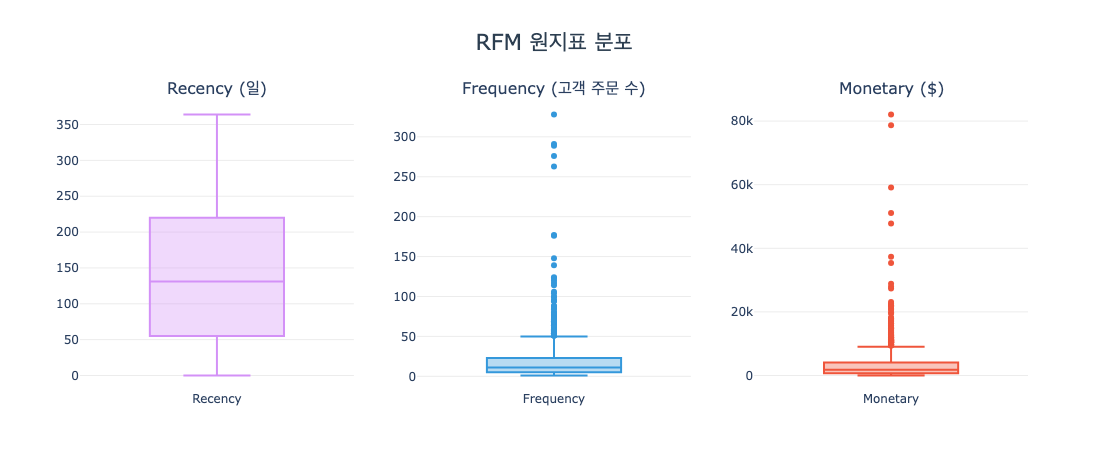

In [24]:
# RFM 원지표의 분포와 이상치를 박스플롯으로 확인한다.
fig = make_subplots(rows=1, cols=3,
    subplot_titles=('Recency (일)', 'Frequency (고객 주문 수)', 'Monetary ($)'))
for col, label, color, fill, pos in [
    ('Recency','Recency','#d391f7','rgba(211,145,247,0.35)',1),
    ('Frequency','Frequency','#3498db','rgba(52,152,219,0.35)',2),
    ('Monetary','Monetary','#EF553B','rgba(239,85,59,0.35)',3),
]:
    fig.add_trace(go.Box(y=rfm[col], name=label, boxpoints='outliers',
                         line=dict(color=color), marker=dict(color=color),
                         fillcolor=fill, showlegend=False), row=1, col=pos)
fig.update_layout(title=dict(text='RFM 원지표 분포', x=0.5,
                             font=dict(size=22,color='#2c3e50')),
                  height=470, plot_bgcolor='white')
fig.update_yaxes(gridcolor='#ececec', zeroline=False)
fig.update_xaxes(showgrid=False)
fig


## RFM 지표 점수화 (1-5점)

RFM 지표 분포를 확인한 결과, 각 지표의 특성에 맞게 점수화 방식을 다르게 적용했다.

### R 점수(Recency 기반, 1–5점) — 분위수 기반 5등분
분포가 비교적 균등한 형태로, 단순 분위수 5등분을 적용했다.  
최근 구매일수록 높은 점수를 부여한다 (역순).

### F 점수(Frequency 기반) / M 점수(Monetary 기반) — IQR 기반 5등분
두 지표 모두 오른쪽 긴 꼬리 분포로 이상치가 존재한다.  
단순 5등분 시 이상치가 일반 고객과 같은 구간에 묶이는 문제가 발생하므로,  
IQR 상한선(`Q3 + 1.5 × IQR`)을 기준으로 이상치를 별도 구간으로 분리한다.

| 점수 | 구간 |
|------|------|
| 1점 | ≤ Q1 |
| 2점 | Q1 - Q2 |
| 3점 | Q2 - Q3 |
| 4점 | Q3 - Q3 + 1.5×IQR |
| 5점 | Q3 + 1.5×IQR 초과 (이상치 구간) |

In [25]:
rfm['R'] = pd.qcut(
    rfm['Recency'],
    q=[0, 0.2, 0.4, 0.6, 0.8, 1.0],
    labels=[5, 4, 3, 2, 1]
).astype(int)

for col in ['Frequency', 'Monetary']:
    q1 = rfm[col].quantile(0.25)
    q2 = rfm[col].quantile(0.50)
    q3 = rfm[col].quantile(0.75)
    upper = q3 + 1.5 * (q3 - q1)
    rfm[col[0]] = pd.cut(
        rfm[col],
        bins=[-np.inf, q1, q2, q3, upper, np.inf],
        labels=[1, 2, 3, 4, 5]
    ).astype(int)



### R·F·M 점수 박스플롯

상자 가운데 선은 중앙값, 상자 범위는 1·3사분위수이며 점은 수염 밖 관측치다.


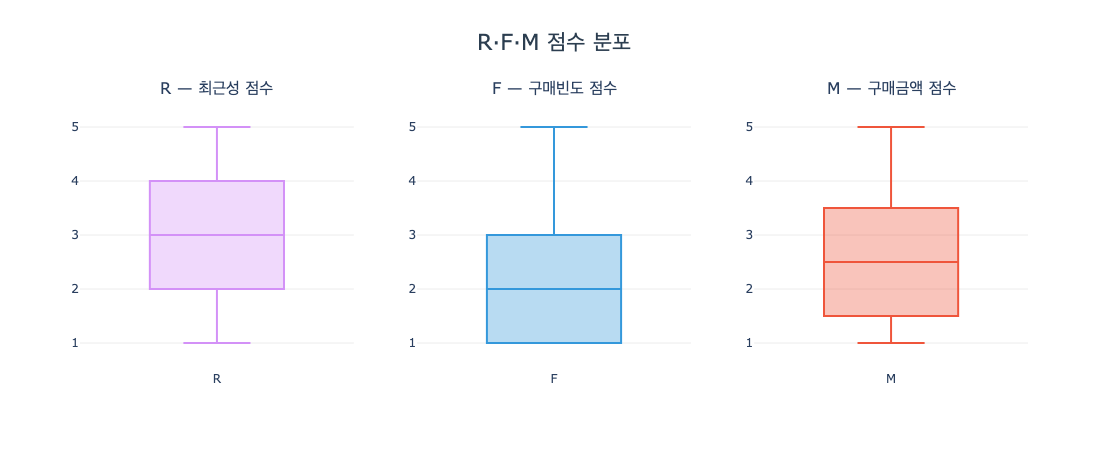

In [26]:
# 1~5점으로 변환한 R·F·M 점수의 중앙값과 사분위 범위를 비교한다.
fig = make_subplots(rows=1, cols=3,
    subplot_titles=('R — 최근성 점수', 'F — 구매빈도 점수', 'M — 구매금액 점수'))
for col, color, fill, pos in [
    ('R','#d391f7','rgba(211,145,247,0.35)',1),
    ('F','#3498db','rgba(52,152,219,0.35)',2),
    ('M','#EF553B','rgba(239,85,59,0.35)',3),
]:
    fig.add_trace(go.Box(y=rfm[col], name=col, boxpoints='outliers',
                         line=dict(color=color), marker=dict(color=color),
                         fillcolor=fill, showlegend=False), row=1, col=pos)
fig.update_layout(title=dict(text='R·F·M 점수 분포', x=0.5,
                             font=dict(size=22,color='#2c3e50')),
                  height=450, plot_bgcolor='white')
fig.update_yaxes(range=[0.5,5.5],dtick=1,gridcolor='#ececec',zeroline=False)
fig.update_xaxes(showgrid=False)
fig


## 보조 탐색: KMeans 군집 구조

KMeans 클러스터링을 수행하기 전, 최적의 클러스터 수(k)를 결정하기 위해 <strong>엘보 방법</strong>와 <strong>실루엣 점수</strong> 두 가지 방법을 함께 사용했다.  
이상치에 민감한 Recency, Frequency, Monetary 원본 수치를 그대로 사용하면 클러스터링 결과가 왜곡될 수 있기 때문에, 이상치에 덜 민감한 <strong>RobustScaler</strong>로 스케일링한 값을 사용했다.

- <strong>엘보 방법</strong>: k가 증가할수록 클러스터 내 분산(Inertia)이 감소하는데, 감소폭이 급격히 줄어드는 지점(꺾이는 지점)을 탐색 후보로 살핀다.
- <strong>실루엣 점수</strong>: 클러스터링의 품질을 평가하는 지표로, 1에 가까울수록 클러스터가 잘 나뉜 것을 의미한다.

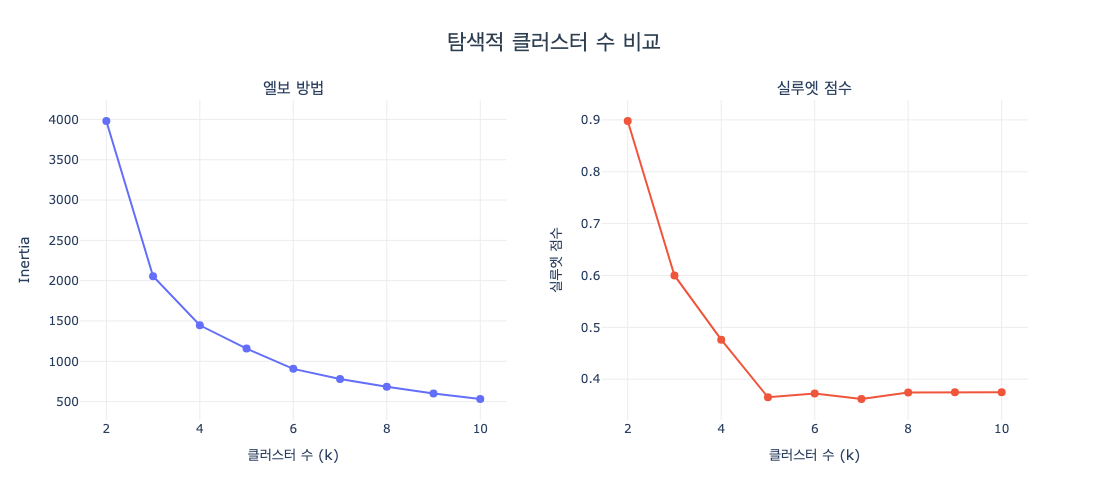

,k,Inertia,실루엣 점수
0,2,3980.82,0.8979
1,3,2054.81,0.6000
2,4,1446.73,0.4761
3,5,1157.82,0.3651
4,6,906.20,0.3726
5,7,781.15,0.3618
6,8,683.45,0.3743
7,9,599.69,0.3746
8,10,532.35,0.3746


In [27]:
features = rfm[['Recency', 'Frequency', 'Monetary']]
scaler = RobustScaler()
scaled_features = pd.DataFrame(
    scaler.fit_transform(features),
    columns=['Recency', 'Frequency', 'Monetary']
)

inertias, silhouette_scores_list = [], []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(scaled_features)
    inertias.append(kmeans.inertia_)
    silhouette_scores_list.append(silhouette_score(scaled_features, labels))

fig = make_subplots(rows=1, cols=2, subplot_titles=('엘보 방법', '실루엣 점수'))

fig.add_trace(
    go.Scatter(x=list(k_range), y=inertias, mode='lines+markers',
               marker=dict(size=8, color='#636EFA'), line=dict(color='#636EFA'),
               showlegend=False),
    row=1, col=1
)
fig.add_trace(
    go.Scatter(x=list(k_range), y=silhouette_scores_list, mode='lines+markers',
               marker=dict(size=8, color='#EF553B'), line=dict(color='#EF553B'),
               showlegend=False),
    row=1, col=2
)

fig.update_layout(
    title=dict(text='탐색적 클러스터 수 비교',
               font=dict(size=22, color='#2c3e50'), x=0.5, xanchor='center'),
    height=500, plot_bgcolor='white'
)
fig.update_xaxes(title_text='클러스터 수 (k)', gridcolor='#ececec')
fig.update_yaxes(gridcolor='#ececec')
fig.update_yaxes(title_text='Inertia', row=1, col=1)
fig.update_yaxes(title_text='실루엣 점수', row=1, col=2)
display(fig)

silhouette_table=pd.DataFrame({'k':list(k_range),'Inertia':inertias,'실루엣 점수':silhouette_scores_list})
display(silhouette_table.round({'Inertia':2,'실루엣 점수':4}))


<strong>탐색 결과</strong>: 실루엣 점수는 k=2에서 가장 높다. 이 결과는 군집 구조를 살피는 보조 탐색이며, 고객 가치 등급 5개를 결정하거나 검증하는 근거로 사용하지 않는다.


In [28]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
rfm_diagnostic = rfm[['고객ID', 'Recency', 'Frequency', 'Monetary']].copy()
rfm_diagnostic['Cluster'] = kmeans.fit_predict(scaled_features)

cluster_summary = rfm_diagnostic.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean().round(2)

cluster_summary=cluster_summary.join(rfm_diagnostic['Cluster'].value_counts().rename('고객수'))
display(cluster_summary.reset_index())


,Cluster,Recency,Frequency,Monetary,고객수
0,0,144.81,16.82,3011.22,1459
1,1,60.78,231.89,49636.50,9


## 가중치 설정하기

R / F / M 세 지표를 하나의 점수로 합산할 때는 <strong>동일 가중치(1/3씩)</strong> 또는 분석가가 정한 수작업 가중치를 사용할 수 있다.  
본 프로젝트에서는 그 대신 PCA의 PC1 절대 로딩을 정규화한 값을 재현 가능한 데이터 의존적 가중 규칙으로 사용했다.

R / F / M 점수(1-5)를 RobustScaler로 스케일링한 뒤 PCA를 적용하면, 첫 번째 주성분(PC1)은 고객 간 분산이 가장 큰 방향을 요약한다.  
각 지표의 PC1 로딩 절댓값을 합이 1이 되도록 정규화한 가중치는 현재 분석 기간의 분산 구조를 종합 점수에 반영하기 위한 규칙이다.

이 가중치는 미래 매출·재방문 예측력, 인과적 중요도 또는 사업적 중요도의 객관적인 추정치가 아니다.  
분석 기간, 스케일링 방식, 고객 분포가 달라지면 가중치도 달라질 수 있으므로 계산 조건을 함께 버전화하고 추후 out-of-time 검증을 수행해야 한다.

### 공식

```
RFM Score = (R × w_r + F × w_f + M × w_m) / 5 × 100  →  20-100점
```

> R / F / M이 모두 1-5점 범위로 산출되므로, 최솟값은 20점(세 지표 모두 1점), 최댓값은 100점(세 지표 모두 5점)이 된다.

In [29]:
X_rfm = rfm[['R', 'F', 'M']]
scaler_pca = RobustScaler()
X_scaled_pca = scaler_pca.fit_transform(X_rfm)

pca = PCA(n_components=1)
pca.fit(X_scaled_pca)

loadings = np.abs(pca.components_[0])
weights = loadings / loadings.sum()
r_w, f_w, m_w = weights

print(f'R 가중치: {r_w:.4f}')
print(f'F 가중치: {f_w:.4f}')
print(f'M 가중치: {m_w:.4f}')
print(f'합계: {r_w + f_w + m_w:.4f}')
print(f'PC1 설명 분산 비율: {pca.explained_variance_ratio_[0]:.3f}')


R 가중치: 0.2007
F 가중치: 0.3392
M 가중치: 0.4601
합계: 1.0000
PC1 설명 분산 비율: 0.694


In [30]:
rfm['RFM_score'] = (
    rfm['R'] * r_w +
    rfm['F'] * f_w +
    rfm['M'] * m_w
) / 5 * 100


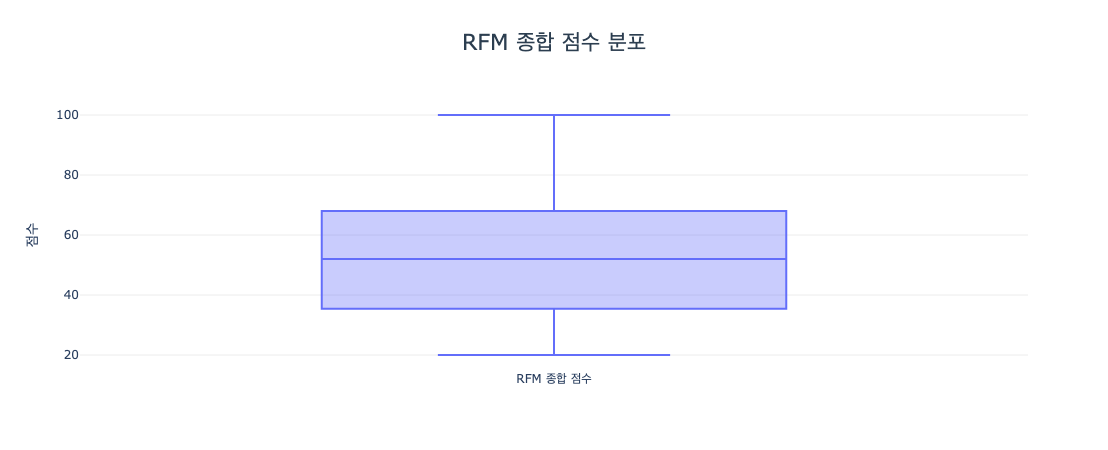

In [31]:
fig = go.Figure(go.Box(y=rfm['RFM_score'], name='RFM 종합 점수',
    boxpoints='outliers', line=dict(color='#636EFA'),
    marker=dict(color='#636EFA'), fillcolor='rgba(99,110,250,0.35)'))
fig.update_layout(title=dict(text='RFM 종합 점수 분포', x=0.5,
                             font=dict(size=22,color='#2c3e50')),
                  height=450, plot_bgcolor='white',showlegend=False)
fig.update_yaxes(title_text='점수',range=[15,105],gridcolor='#ececec',zeroline=False)
fig.update_xaxes(showgrid=False)
fig


## 5. 가치 등급과 행동 세그먼트

RFM 종합 점수에 운영 컷오프를 적용한다: Diamond ≥95, Platinum ≥80, Gold ≥65, Silver ≥50, 나머지는 Bronze다. 컷오프는 CRM 운영 규칙이며 자연 군집의 경계나 미래 성과 검증값이 아니다. 11개 행동 세그먼트는 R·F·M 점수 조합으로 정한다. 등급과 세그먼트는 같은 기간의 구매 이력에서 계산한 분류다.


In [32]:
rfm['등급'] = np.select(
    [rfm['RFM_score'].ge(95), rfm['RFM_score'].ge(80),
     rfm['RFM_score'].ge(65), rfm['RFM_score'].ge(50)],
    ['Diamond','Platinum','Gold','Silver'], default='Bronze'
)


In [33]:
display(rfm['등급'].value_counts().rename_axis('등급').reset_index(name='고객수'))


,등급,고객수
0,Bronze,698
1,Silver,315
2,Gold,243
3,Platinum,154
4,Diamond,58


### 활성·성장 세그먼트

| 세그먼트 | 원문 | 특징 | 점수 조합 |
|---------|------|------|----------|
| VIP 고객 | Champions | 최근에 자주, 많이 구매한 핵심 고객 | 555, 554, 544, 545, 454, 455, 445 |
| 충성 고객 | Loyal | 지속적으로 구매하는 충성 고객 | 543, 444, 435, 355, 354, 345, 344, 335 |
| 잠재 충성 고객 | Potential Loyalist | 최근 구매했고 충성 고객이 될 가능성이 높은 고객 | 553, 551, 552, 541, 542, 533, 532, 531, 452, 451, 442, 441, 431, 453, 433, 432, 423, 353, 352, 351, 342, 341, 333, 323 |
| 최근·저빈도 고객 | New Customers | 최근 구매했지만 F·M이 낮은 고객(실제 신규 여부는 알 수 없음) | 512, 511, 422, 421, 412, 411, 311 |
| 가망 고객 | Promising | 최근 구매했지만 빈도·금액이 아직 낮은 고객 | 525, 524, 523, 522, 521, 515, 514, 513, 425, 424, 413, 414, 415, 315, 314, 313 |
| 관심 필요 고객 | Need Attention | 평균 수준이나 최근성이 떨어지기 시작한 고객 | 535, 534, 443, 434, 343, 334, 325, 324 |

### 이탈·비활성 세그먼트

| 세그먼트 | 원문 | 특징 | 점수 조합 |
|---------|------|------|----------|
| 이탈 조짐 고객 | About to Sleep | 구매 간격이 벌어지고 있는 이탈 위험 고객 | 331, 321, 312, 221, 213, 231, 241, 251 |
| 놓치면 안될 고객 | Cannot Lose Them | 과거 고가치였지만 오랫동안 구매하지 않은 고객 | 155, 154, 144, 214, 215, 115, 114, 113 |
| 이탈 위험 고객 | At Risk | 예전에 자주 샀지만 최근 방문이 없는 고객 | 255, 254, 245, 244, 253, 252, 243, 242, 235, 234, 225, 224, 153, 152, 145, 143, 142, 135, 134, 133, 125, 124 |
| 휴면 고객 | Hibernating | 오랫동안 비활성 상태인 고객 | 332, 322, 233, 232, 223, 222, 132, 123, 122, 212, 211 |
| 이탈 고객 | Lost | 완전히 이탈한 것으로 보이는 고객 | 111, 112, 121, 131, 141, 151 |

In [34]:
segment_code_groups = {
    'VIP 고객': '555 554 544 545 454 455 445'.split(),
    '충성 고객': '543 444 435 355 354 345 344 335'.split(),
    '잠재 충성 고객': '553 551 552 541 542 533 532 531 452 451 442 441 431 453 433 432 423 353 352 351 342 341 333 323'.split(),
    '최근·저빈도 고객': '512 511 422 421 412 411 311'.split(),
    '가망 고객': '525 524 523 522 521 515 514 513 425 424 413 414 415 315 314 313'.split(),
    '관심 필요 고객': '535 534 443 434 343 334 325 324'.split(),
    '이탈 조짐 고객': '331 321 312 221 213 231 241 251'.split(),
    '놓치면 안될 고객': '155 154 144 214 215 115 114 113'.split(),
    '이탈 위험 고객': '255 254 245 244 253 252 243 242 235 234 225 224 153 152 145 143 142 135 134 133 125 124'.split(),
    '휴면 고객': '332 322 233 232 223 222 132 123 122 212 211'.split(),
    '이탈 고객': '111 112 121 131 141 151'.split(),
}
segment_rules = {code: label for label, codes in segment_code_groups.items() for code in codes}
codes=rfm[['R','F','M']].astype(str).agg(''.join,axis=1)
rfm['세그먼트']=codes.map(segment_rules).fillna('Others')

assert len(segment_rules) == 125
assert rfm['세그먼트'].ne('Others').all()


In [35]:
display(rfm['세그먼트'].value_counts().rename_axis('세그먼트').reset_index(name='고객수'))


,세그먼트,고객수
0,휴면 고객,355
1,최근·저빈도 고객,220
2,잠재 충성 고객,205
3,VIP 고객,135
4,이탈 고객,129
5,충성 고객,116
6,이탈 위험 고객,103
7,가망 고객,63
8,관심 필요 고객,51
9,이탈 조짐 고객,47


### RFM 결과의 MySQL 저장

로컬에서 계산한 점수와 분류 결과를 `rfm_scores`, `rfm_result`로 저장한다. 위 MySQL 적재를 실행한 경우에만 이 셀도 실행된다.


In [36]:
if RUN_MYSQL_LOAD:
    rfm_scores = rfm[['고객ID','R','F','M','RFM_score',
                      'Recency','Frequency','Monetary']]
    rfm_scores.to_sql('rfm_scores', con=engine, if_exists='replace', index=False)
    rfm.to_sql('rfm_result', con=engine, if_exists='replace', index=False)
    for tbl in ['rfm_scores','rfm_result']:
        cnt = pd.read_sql(f'SELECT COUNT(*) AS n FROM {tbl}', engine).iloc[0,0]
        assert cnt == len(rfm)
        print(f'{tbl}: {cnt:,}행')
else:
    print('RFM MySQL 적재 미실행: RUN_MYSQL_LOAD=False')


RFM MySQL 적재 미실행: RUN_MYSQL_LOAD=False


## 6. 고객 구매 이력과 분석 테이블 검산

상품라인 `sales_lines`, 고객 주문 `analysis_orders`, 고객별 RFM·방문 지표 `analysis_customers`를 구분한다. <strong>연간 재구매 고객 비율</strong>은 서로 다른 날 2일 이상 구매한 고객을 전체 고객으로 나눈 값이다. <strong>첫 구매 다음 달 재구매율</strong>은 2019년 거래에서 첫 구매가 확인된 달을 기준으로, 다음 달을 관찰할 수 있는 고객 중 다시 구매한 고객의 비율이다. 따라서 12월 첫 구매 고객은 이 비율의 분모에서 제외한다. 여기서 첫 구매는 실제 생애 첫 구매와 다르다.


In [37]:
history = (analysis_orders.groupby('고객ID', as_index=False)
    .agg(첫구매일=('거래날짜','min'), 마지막구매일=('거래날짜','max')))
visit_days = (analysis_orders.assign(구매일=analysis_orders['거래날짜'].dt.normalize())
    .groupby('고객ID')['구매일'].nunique().rename('구매일수'))
analysis_customers = (rfm.merge(history,on='고객ID',validate='one_to_one')
    .merge(visit_days,on='고객ID',validate='one_to_one'))
analysis_customers['다른날재방문'] = analysis_customers['구매일수'].gt(1)

customer_month = (analysis_orders.assign(구매월=analysis_orders['거래날짜'].dt.month)
    [['고객ID','구매월']].drop_duplicates())
analysis_customers['관측첫구매월'] = analysis_customers['첫구매일'].dt.month
analysis_customers['다음달관찰가능'] = analysis_customers['관측첫구매월'].lt(12)
next_month = customer_month.merge(
    analysis_customers[['고객ID','관측첫구매월']], on='고객ID', validate='many_to_one')
returned = next_month.loc[
    next_month['구매월'].eq(next_month['관측첫구매월']+1), '고객ID']
analysis_customers['첫구매월+1개월복귀'] = (
    analysis_customers['고객ID'].isin(returned) & analysis_customers['다음달관찰가능'])
analysis_customers['대표상태'] = analysis_customers['세그먼트'].map(
    {'잠재 충성 고객':'잠재 충성','이탈 위험 고객':'이탈 위험'}).fillna('그 외')
analysis_customers['장기미방문_90일예시'] = analysis_customers['Recency'].gt(90)


In [38]:
assert len(sales_lines) == 52924
assert len(analysis_orders) == 26631
assert len(analysis_customers) == 1468 and analysis_customers['고객ID'].is_unique
assert round(sales_lines['세후금액'].sum(),2) == 4840102.19
assert round(analysis_orders['배송비'].sum(),2) == 238987.60
assert round(analysis_orders['고객결제액'].sum(),2) == 5079089.79
assert round(sales_lines['배송비_배부액'].sum(),2) == 238987.60
assert analysis_customers['다른날재방문'].sum() == 734
eligible = analysis_customers['다음달관찰가능']
assert eligible.sum() == 1362
assert analysis_customers.loc[eligible,'첫구매월+1개월복귀'].sum() == 130
assert analysis_customers['Frequency'].sum() == len(analysis_orders)
assert analysis_customers['세그먼트'].ne('Others').all()
print("분석 데이터 확인: 상품라인 52,924 · 고객 주문 26,631 · 고객 1,468")
print("연간 재구매 고객 비율 734/1,468 = 50.0%")
print("첫 구매 다음 달 재구매율 130/1,362 = 9.54%")


분석 데이터 확인: 상품라인 52,924 · 고객 주문 26,631 · 고객 1,468
연간 재구매 고객 비율 734/1,468 = 50.0%
첫 구매 다음 달 재구매율 130/1,362 = 9.54%
